# 10.1 Gingival failure audit

Executed validation audit; no training or test evaluation.

```mermaid
flowchart LR
    A[Locked validation inputs] --> B[Verify identities and processing]
    B --> C[Recompute metrics and inspect errors]
    C --> D[Save evidence and decide next experiment]
```

## 1. Scope and reproducibility
Use existing validation predictions. Test pixels remain unopened; clinical labels remain unchanged.

In [1]:
from pathlib import Path
import hashlib, json, platform, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter, ImageEnhance
from IPython.display import display, Markdown
ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src/dentalselfie').exists(), 'Run from project root or notebooks directory'
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2), encoding='utf-8')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print('Root:', ROOT, '| Python:', platform.python_version())

OUT = ROOT / 'docs/reports/post09/gingival'
OUT.mkdir(parents=True, exist_ok=True)
RAW = ROOT / 'data/processed/gum_raw_roi_v1'
OLD = ROOT / 'data/processed/gum_roi_v1'
raw_receipt = json.loads((RAW / 'receipt.json').read_text())
assert sha(RAW / 'manifest.csv') == raw_receipt['manifest_sha256']
assert sha(OLD / 'manifest.csv') == raw_receipt['signature']['roi_v1_manifest_sha256']
manifest = pd.read_csv(RAW / 'manifest.csv')
old = pd.read_csv(OLD / 'manifest.csv')
keys = ['crop_id','parent_id','group_id','split','class_id']
pd.testing.assert_frame_equal(manifest[keys].sort_values('crop_id').reset_index(drop=True),
                             old[keys].sort_values('crop_id').reset_index(drop=True))
for task in ['gum', 'caries']:
    lock = json.loads((ROOT / f'data/manifests/{task}.lock.json').read_text())
    assert sha(ROOT / f'data/manifests/{task}.splits.csv') == lock['splits_sha256']
val = manifest[manifest.split.eq('val')].copy().set_index('crop_id')
assert len(val) == 1920 and manifest.groupby('group_id').split.nunique().max() == 1
print('Verified manifest identities and both split locks; validation crops:', len(val))

Root: C:\Users\huynh\Desktop\oral-disease | Python: 3.11.15
Verified manifest identities and both split locks; validation crops: 1920


## 2. Original label semantics and independent support
Classes are source-defined appearance groups. Jaw boxes 0/1 are excluded. Group counts describe observable source constraints, not verified patients. Count source annotation IDs without opening test files.

,source_id,mapped_class
0,0,NaN
1,1,NaN
2,2,0.0
3,3,1.0
4,4,1.0
5,5,2.0
6,6,2.0


2026-10-20: source Table 2 and labeling section, caption checks 00929/00001/00733, and standard-versus-swapped overlays. Standard normalized width/height align anatomically; jaw ROIs 0/1 are excluded. Measured counts are reported separately from published counts.

,split,class_id,class_name,crops,parents,groups
0,train,0,no_visible_inflammation,210,87,87
1,train,1,mild_inflammation,3829,592,592
2,train,2,marked_inflammation,4930,651,651
3,val,0,no_visible_inflammation,49,23,23
4,val,1,mild_inflammation,932,132,132
5,val,2,marked_inflammation,939,133,133


class_name                   marked_inflammation  mild_inflammation  \
split original_source_class                                           
train 2                                        0                  0   
      3                                        0               1157   
      4                                        0               2672   
      5                                     3391                  0   
      6                                     1539                  0   
val   2                                        0                  0   
      3                                        0                351   
      4                                        0                581   
      5                                      623                  0   
      6                                      316                  0   

class_name                   no_visible_inflammation  
split original_source_class                           
train 2                                          210  
      3                                            0  
      4                                            0  
      5                                            0  
      6                                            0  
val   2                                           49  
      3                                            0  
      4                                            0  
      5                                            0  
      6                                            0

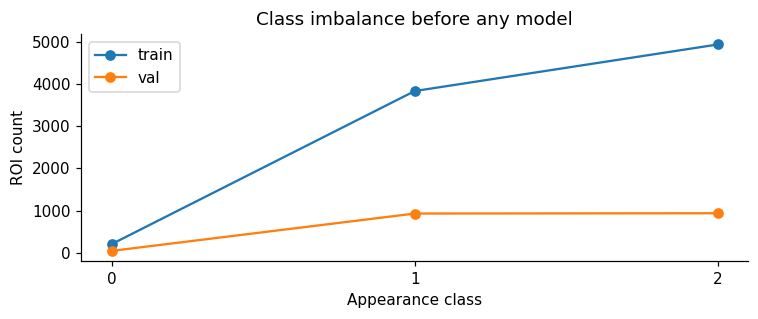

In [2]:
mapping = json.loads((ROOT / 'src/configs/label_mappings.json').read_text())['gum']
assert mapping['classes'] == {'0':None,'1':None,'2':0,'3':1,'4':1,'5':2,'6':2}
display(pd.DataFrame([{'source_id': k, 'mapped_class': v} for k,v in mapping['classes'].items()]))
display(Markdown(mapping['evidence']))
support = manifest.groupby(['split','class_id','class_name']).agg(
    crops=('crop_id','size'), parents=('parent_id','nunique'), groups=('group_id','nunique')).reset_index()
support.to_csv(OUT / 'class_group_support.csv', index=False)
display(support)
parents = pd.read_csv(ROOT / 'data/manifests/gum.splits.csv').set_index('sample_id')
source_ids = {}
for pid, group in manifest.groupby('parent_id'):
    parent = parents.loc[pid]
    label_path = ROOT / parent.source_label
    assert parent.split in ['train','val'] and sha(label_path) == parent.source_label_sha256
    lines = label_path.read_text().splitlines()
    for row in group.itertuples():
        source_id = lines[int(row.source_annotation_line)].split()[0]
        assert mapping['classes'][source_id] == row.class_id
        source_ids[row.crop_id] = source_id
manifest['original_source_class'] = manifest.crop_id.map(source_ids)
display(pd.crosstab([manifest.split, manifest.original_source_class], manifest.class_name))
fig, ax = plt.subplots(figsize=(7,3))
for split, group in support.groupby('split'):
    ax.plot(group.class_id, group.crops, marker='o', label=split)
ax.set(xticks=[0,1,2], xlabel='Appearance class', ylabel='ROI count', title='Class imbalance before any model')
ax.legend(); fig.tight_layout(); fig.savefig(OUT/'class_support.png'); plt.show()

## 3. Recompute every available full-run prediction table
Exclude smoke runs and the invalid scratch initialization version. Some 6.x artifacts contain only aggregate metrics: report that limitation rather than invent per-crop predictions. All comparisons here remain exploratory.

In [3]:
def matrix_metrics(cm):
    recall = np.divide(cm.diagonal(), cm.sum(1), out=np.zeros(3), where=cm.sum(1)>0)
    precision = np.divide(cm.diagonal(), cm.sum(0), out=np.zeros(3), where=cm.sum(0)>0)
    f1 = np.divide(2*precision*recall, precision+recall, out=np.zeros(3), where=(precision+recall)>0)
    return {'accuracy': float(cm.trace()/cm.sum()), 'macro_f1': float(f1.mean()),
            'balanced_accuracy': float(recall.mean())}
prediction_paths = []
for run in ['ROI_07_1_v1','ROI_07_2_v1','ROI_09_1_v1','ROI_09_2_v1','ROI_09_3_v3']:
    prediction_paths += [p for p in (ROOT/'data/runs'/run).rglob('validation_predictions.csv') if 'smoke' not in p.parts]
joined = val.copy()
rows, evidence = [], []
for path in sorted(prediction_paths):
    pred = pd.read_csv(path)
    assert pred.crop_id.is_unique and set(pred.crop_id) == set(val.index)
    pred = pred.set_index('crop_id').loc[val.index]
    assert np.array_equal(pred.true_class, val.class_id)
    assert pred.predicted_class.isin([0,1,2]).all()
    metrics = json.loads(path.with_name('metrics.json').read_text())
    cm = np.zeros((3,3), dtype=int)
    np.add.at(cm, (pred.true_class.to_numpy(), pred.predicted_class.to_numpy()), 1)
    assert cm.tolist() == metrics['confusion_matrix']
    measured = matrix_metrics(cm)
    for k, v in measured.items(): assert np.isclose(v, metrics[k]), (path,k)
    probabilities = np.array(pred.probabilities.map(json.loads).tolist())
    ordinal = bool(metrics.get('ordinal', False))
    if ordinal:
        assert probabilities.shape[1] == 2 and (probabilities[:,0] >= probabilities[:,1]).all()
        decoded = (probabilities > .5).sum(1)
    else:
        assert np.allclose(probabilities.sum(1), 1, atol=.002)
        decoded = probabilities.argmax(1)
    assert np.array_equal(decoded, pred.predicted_class)
    history_path = path.with_name('history.csv')
    if history_path.exists():
        history = pd.read_csv(history_path)
        best = history.loc[history.macro_f1.idxmax()]
        assert int(best.epoch) == int(metrics['selected_epoch'])
        assert np.isclose(best.macro_f1, metrics['macro_f1'])
    name = path.parent.name
    joined['pred_'+name] = pred.predicted_class
    rows.append({'experiment':name, **measured, 'no_visible_recall':cm[0,0]/cm[0].sum()})
    evidence.append({'experiment':name,'predictions_sha256':sha(path),'metrics_sha256':sha(path.with_name('metrics.json'))})
results = pd.DataFrame(rows).sort_values('macro_f1', ascending=False)
results.to_csv(OUT/'verified_model_metrics.csv',index=False)
display(results.style.format({k:'{:.2%}' for k in ['accuracy','macro_f1','balanced_accuracy','no_visible_recall']}))
print('Verified per-crop runs:',len(results),'| Historical 6.x aggregate-only results remain in their original report.')

,experiment,accuracy,macro_f1,balanced_accuracy,no_visible_recall
6,R2_raw_CBCE,69.11%,57.40%,60.16%,40.82%
5,R1_raw_CE,68.70%,57.26%,58.61%,36.73%
4,R0_old_CE,68.07%,56.61%,60.11%,42.86%
1,M2_gate_CE,67.03%,53.99%,59.37%,42.86%
0,M1_concat_CE,69.53%,53.60%,53.34%,18.37%
7,R3_raw_BalancedSoftmax,67.03%,53.36%,56.15%,32.65%
2,M3_local_CORAL,63.28%,51.46%,63.86%,65.31%
8,P0_raw_frozen_ResNet18,66.67%,50.08%,50.10%,14.29%
3,M4_gate_CORAL,63.65%,49.48%,56.37%,40.82%
9,P1_raw_frozen_DINOv3,67.97%,47.83%,47.77%,4.08%


Verified per-crop runs: 10 | Historical 6.x aggregate-only results remain in their original report.


## 4. Shared failures versus model disagreement
Agreement does not establish label correctness. These are correlated models trained on the same source. Identify hard examples without relabelling them.

,crops,all_wrong,unanimous_wrong,all_correct
class_name,,,,
marked_inflammation,939,23,13,408
mild_inflammation,932,62,61,111
no_visible_inflammation,49,14,5,0


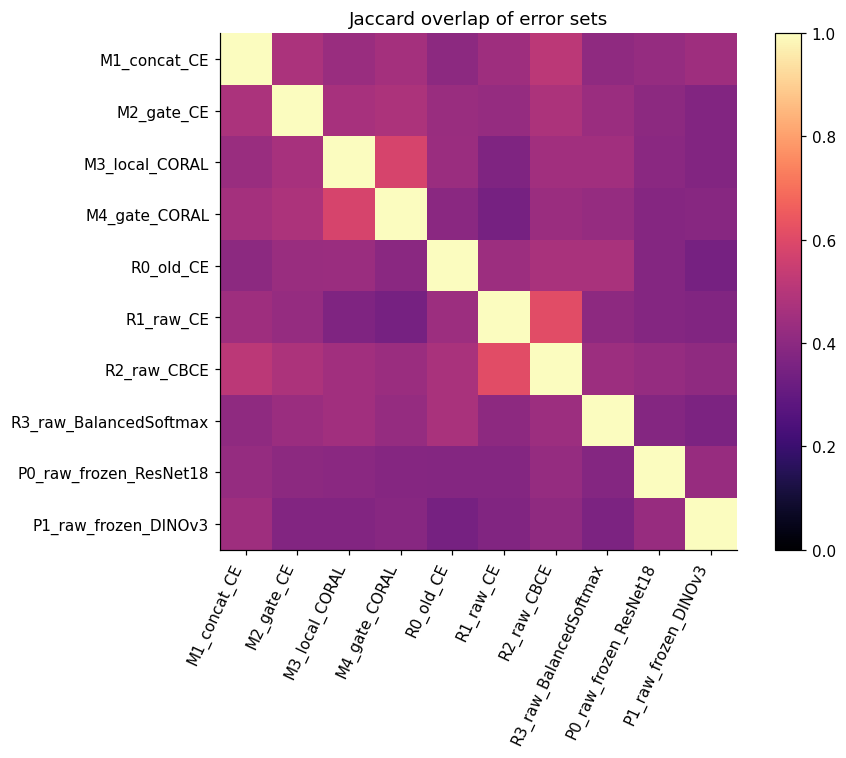

In [4]:
pred_cols = [c for c in joined if c.startswith('pred_')]
pred_array = joined[pred_cols].to_numpy()
joined['wrong_count'] = (pred_array != joined.class_id.to_numpy()[:,None]).sum(1)
joined['all_wrong'] = joined.wrong_count.eq(len(pred_cols))
joined['all_correct'] = joined.wrong_count.eq(0)
joined['unanimous'] = np.array([len(set(row)) == 1 for row in pred_array])
joined['unanimous_wrong'] = joined.unanimous & joined.all_wrong
display(joined.groupby('class_name').agg(crops=('class_id','size'),all_wrong=('all_wrong','sum'),
                                       unanimous_wrong=('unanimous_wrong','sum'),all_correct=('all_correct','sum')))
error_matrix = (pred_array != joined.class_id.to_numpy()[:,None]).T.astype(float)
intersection = error_matrix @ error_matrix.T
union = error_matrix.sum(1)[:,None] + error_matrix.sum(1)[None,:] - intersection
jaccard = np.divide(intersection, union, out=np.zeros_like(intersection), where=union>0)
fig,ax=plt.subplots(figsize=(9,7)); im=ax.imshow(jaccard,vmin=0,vmax=1,cmap='magma')
labels=[c.removeprefix('pred_') for c in pred_cols]
ax.set(xticks=range(len(labels)),yticks=range(len(labels)),xticklabels=labels,yticklabels=labels,title='Jaccard overlap of error sets')
plt.setp(ax.get_xticklabels(),rotation=65,ha='right'); fig.colorbar(im,ax=ax); fig.tight_layout()
fig.savefig(OUT/'error_overlap.png'); plt.show()

## 5. Verify validation crop bytes and measure quality proxies
Laplacian variance and grayscale brightness are descriptive image statistics, not clinical quality judgments. Fixed bins are reported on the complete validation set; no image is excluded.

In [5]:
import cv2
quality = []
for crop_id, row in val.iterrows():
    path = RAW / row.local_path
    assert sha(path) == row.local_sha256
    with Image.open(path) as image:
        assert image.size == (224,224) and image.mode == 'RGB'
        gray = np.asarray(image.convert('L'),dtype=np.uint8)
    quality.append({'crop_id':crop_id,'brightness':float(gray.mean()),
                    'laplacian_variance':float(cv2.Laplacian(gray,cv2.CV_64F).var())})
joined = joined.join(pd.DataFrame(quality).set_index('crop_id'))
joined['source_min_edge'] = joined[['raw_box_width','raw_box_height']].min(axis=1)
joined['size_bin'] = pd.cut(joined.source_min_edge, [0,224,448,np.inf], labels=['<=224','225-448','>448'])
joined['brightness_bin'] = pd.cut(joined.brightness, [-1,64,128,192,256], labels=['0-64','65-128','129-192','193-255'])
joined['sharpness_bin'] = pd.cut(joined.laplacian_variance, [-1,100,500,np.inf], labels=['<=100','101-500','>500'])
strata=[]
for variable in ['size_bin','brightness_bin','sharpness_bin']:
    for name, subset in joined.groupby(variable,observed=True):
        cm=np.zeros((3,3),int)
        np.add.at(cm,(subset.class_id,subset.pred_R1_raw_CE),1)
        strata.append({'stratum':variable,'bin':str(name),'crops':len(subset),
                       'source_groups':subset.group_id.nunique(),'class_support':cm.sum(1).tolist(),
                       **matrix_metrics(cm)})
strata=pd.DataFrame(strata); strata.to_csv(OUT/'quality_strata.csv',index=False); display(strata)
print('Macro-F1 uses the fixed three classes; absent classes in small strata receive zero F1.')

,stratum,bin,crops,source_groups,class_support,accuracy,macro_f1,balanced_accuracy
0,size_bin,225-448,270,81,"[5, 153, 112]",0.718519,0.633838,0.677533
1,size_bin,>448,1650,159,"[44, 779, 827]",0.681818,0.563512,0.574746
2,brightness_bin,0-64,6,4,"[0, 0, 6]",1.000000,0.333333,0.333333
3,brightness_bin,65-128,1699,160,"[37, 780, 882]",0.685109,0.587986,0.613622
4,brightness_bin,129-192,215,62,"[12, 152, 51]",0.693023,0.473828,0.473942
5,sharpness_bin,<=100,1913,160,"[49, 931, 933]",0.686357,0.572211,0.585625
6,sharpness_bin,101-500,7,6,"[0, 1, 6]",0.857143,0.307692,0.333333


Macro-F1 uses the fixed three classes; absent classes in small strata receive zero F1.


## 6. Blinded clinical review sheet and representative galleries
Include every no-visible ROI, a fixed random sample of the other classes, and a separately identified hard-case sample. The blinded sheet omits model predictions; technical statistics remain in a separate file. Empty review fields are intentional and require a qualified reviewer.

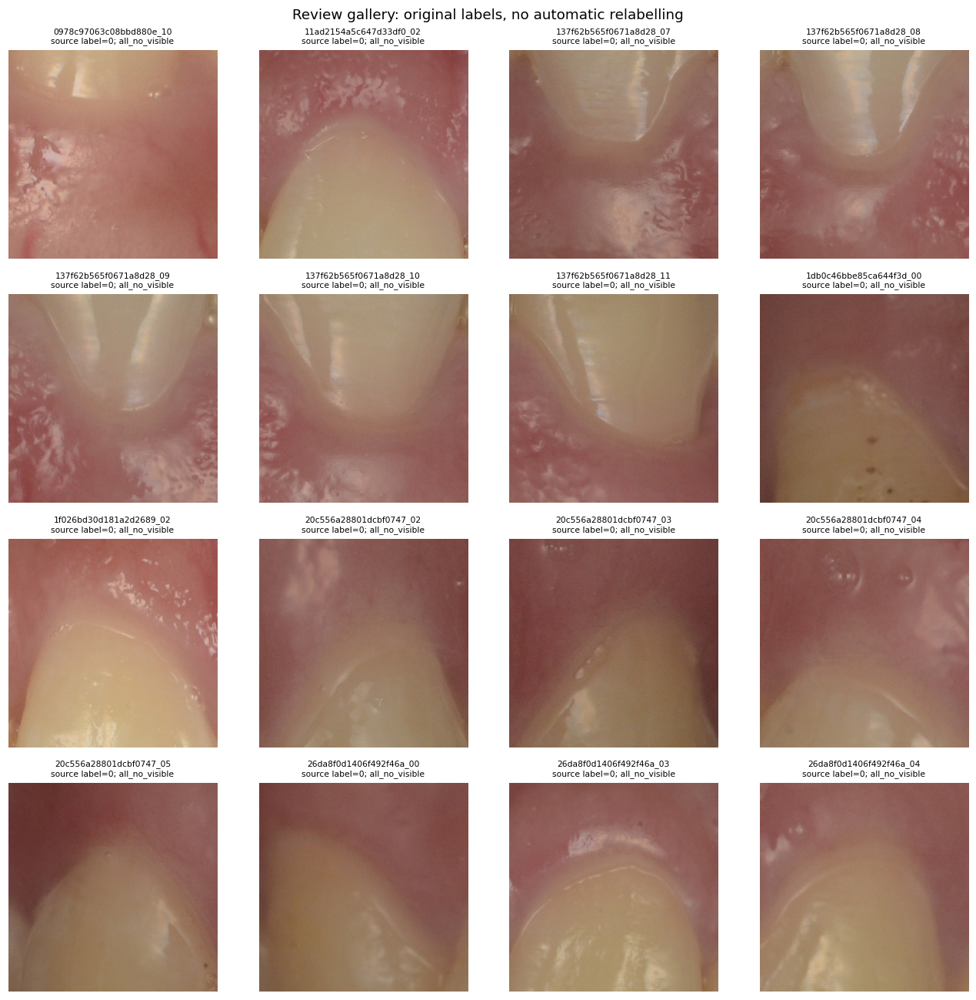

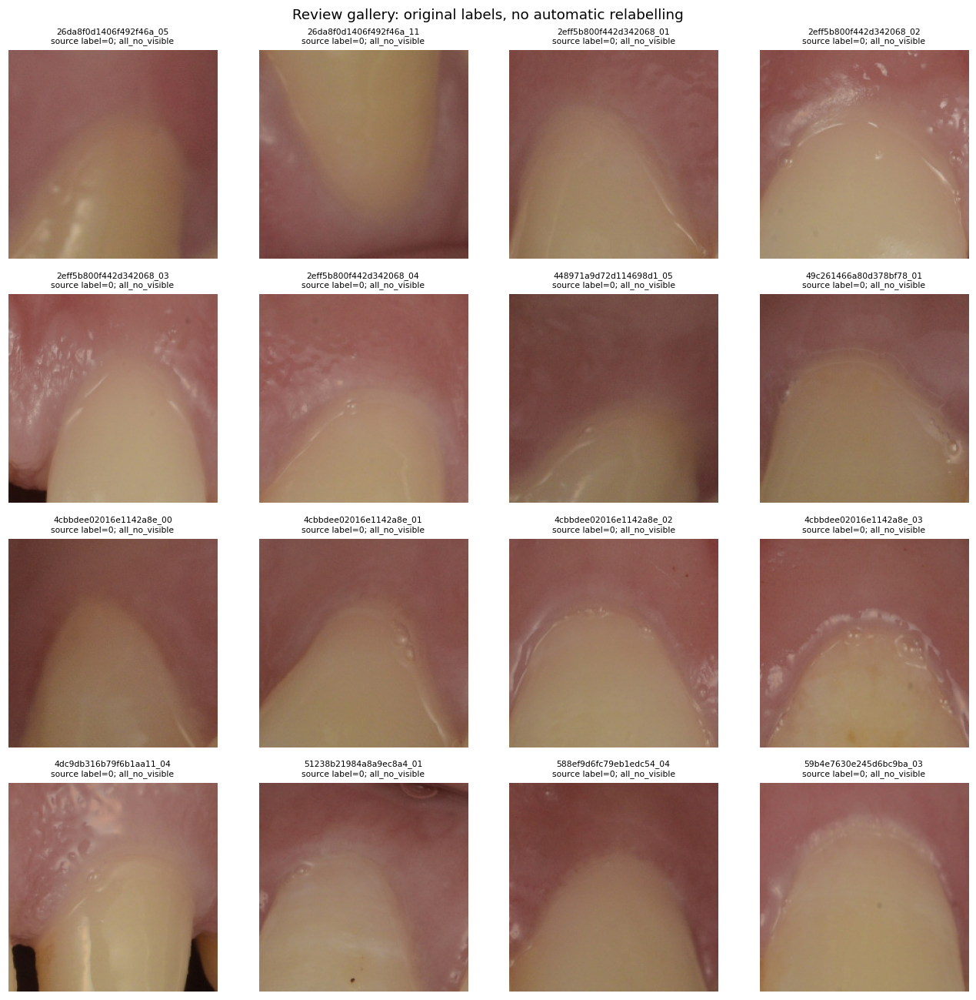

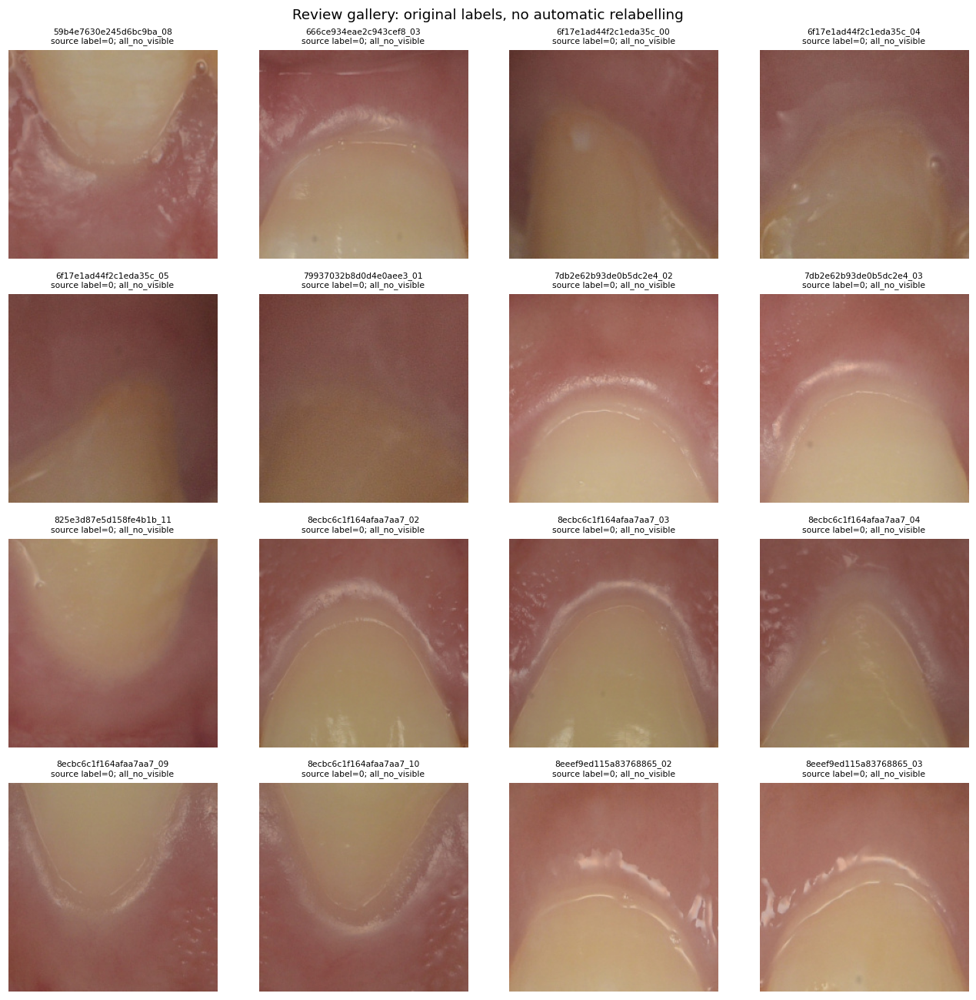

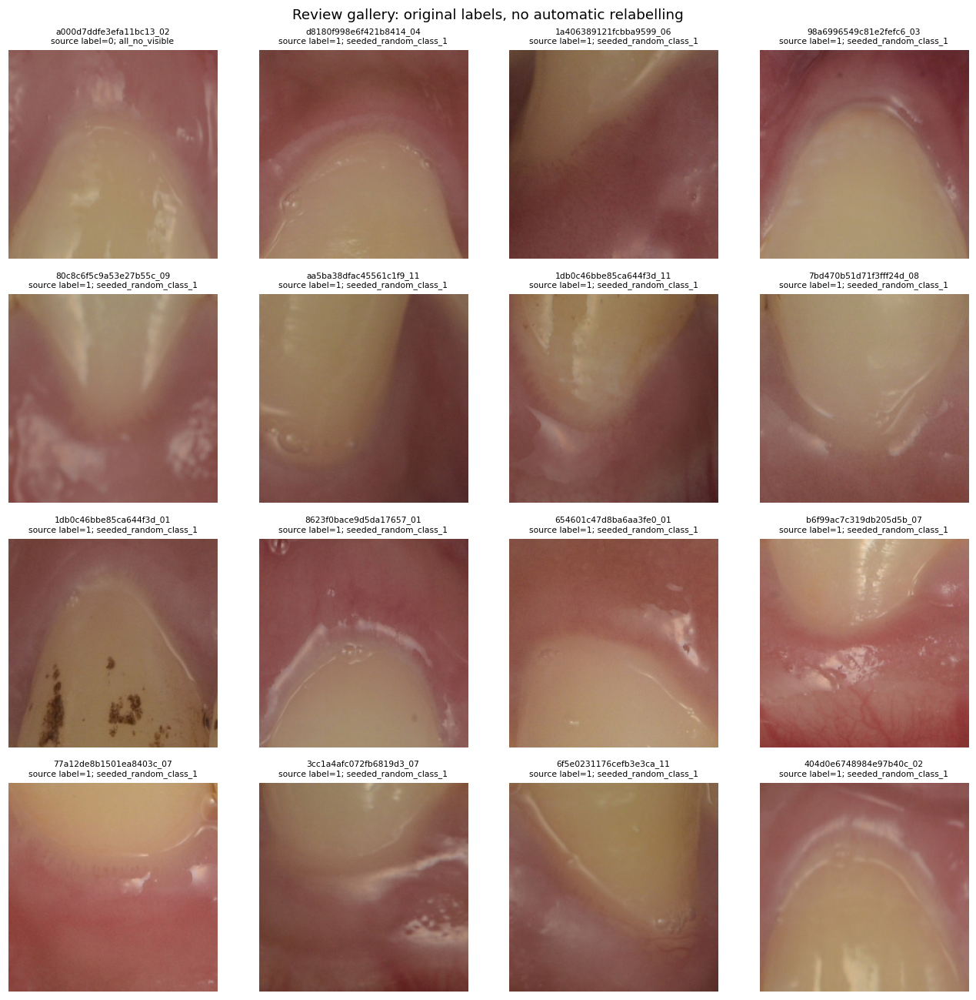

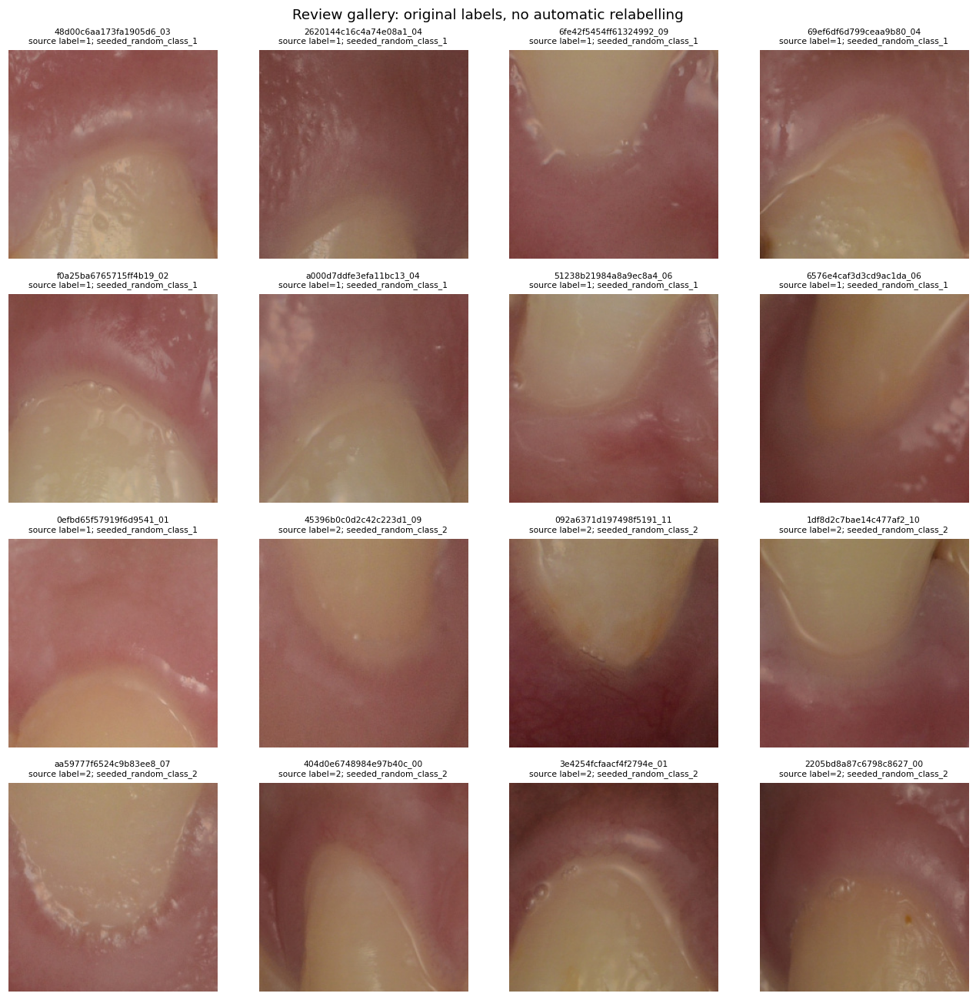

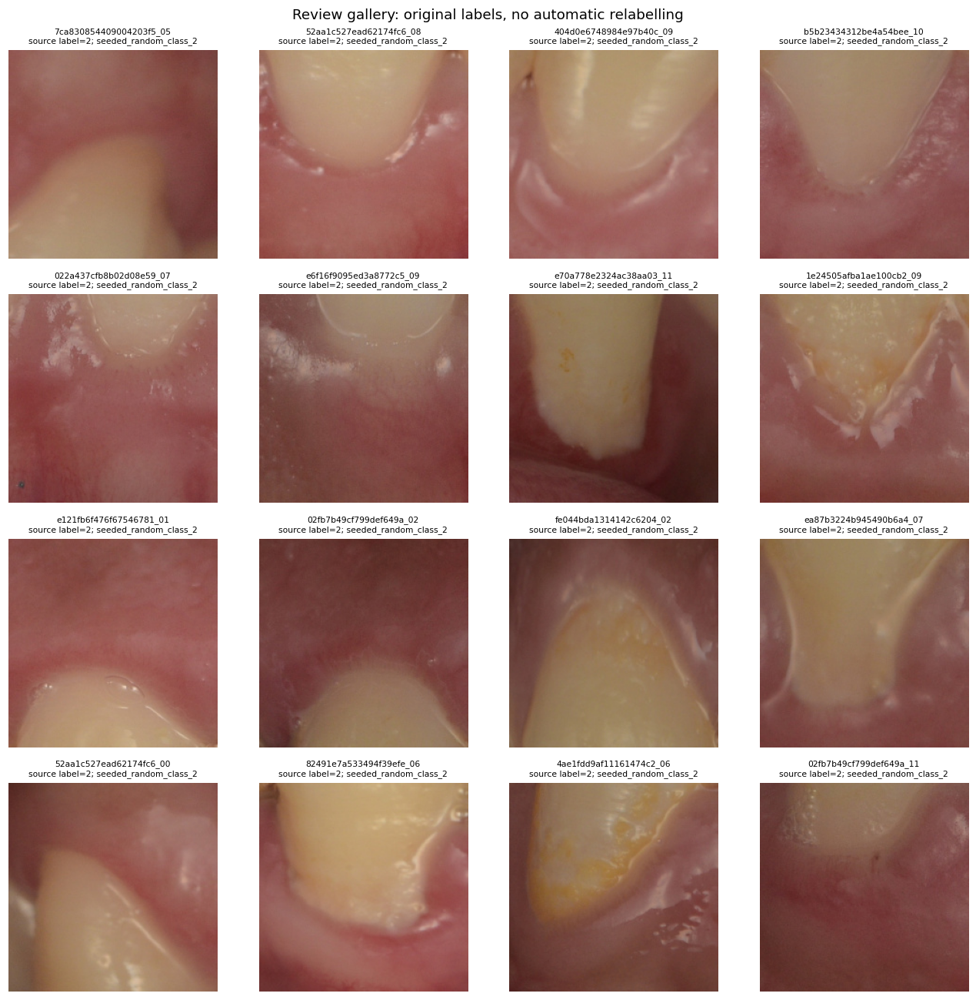

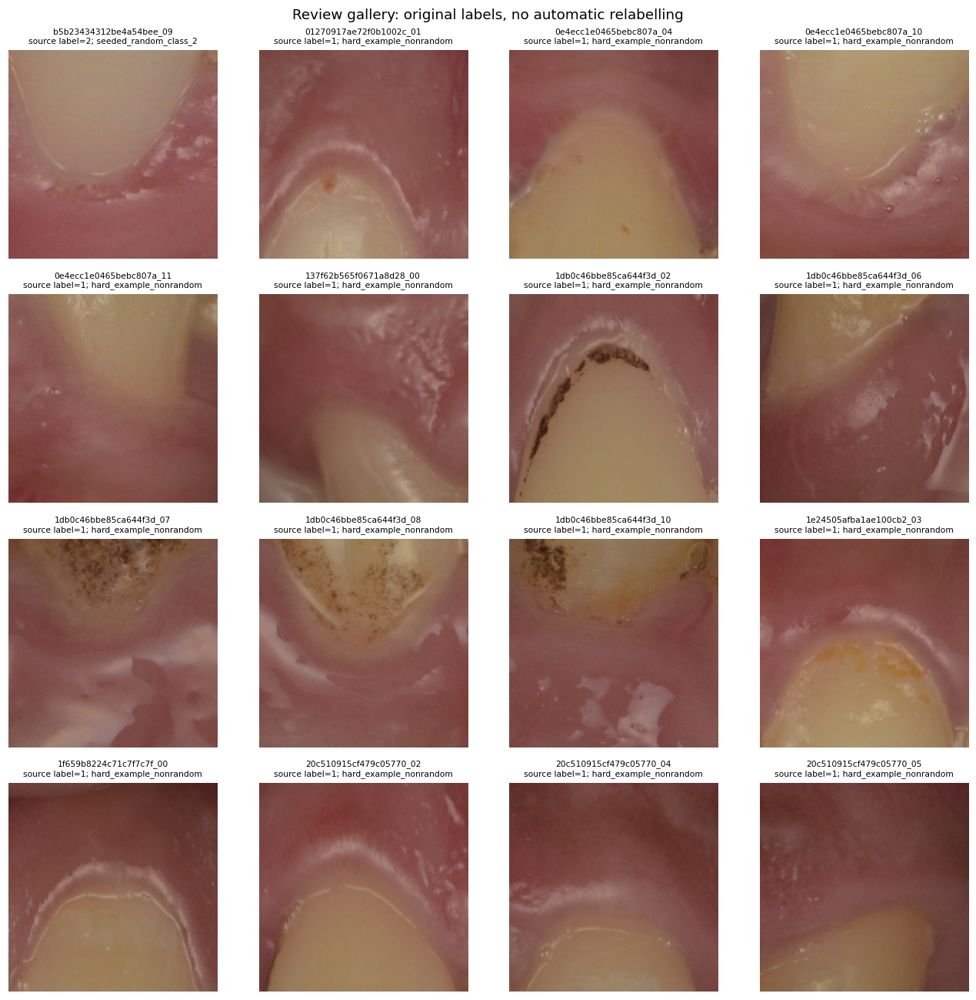

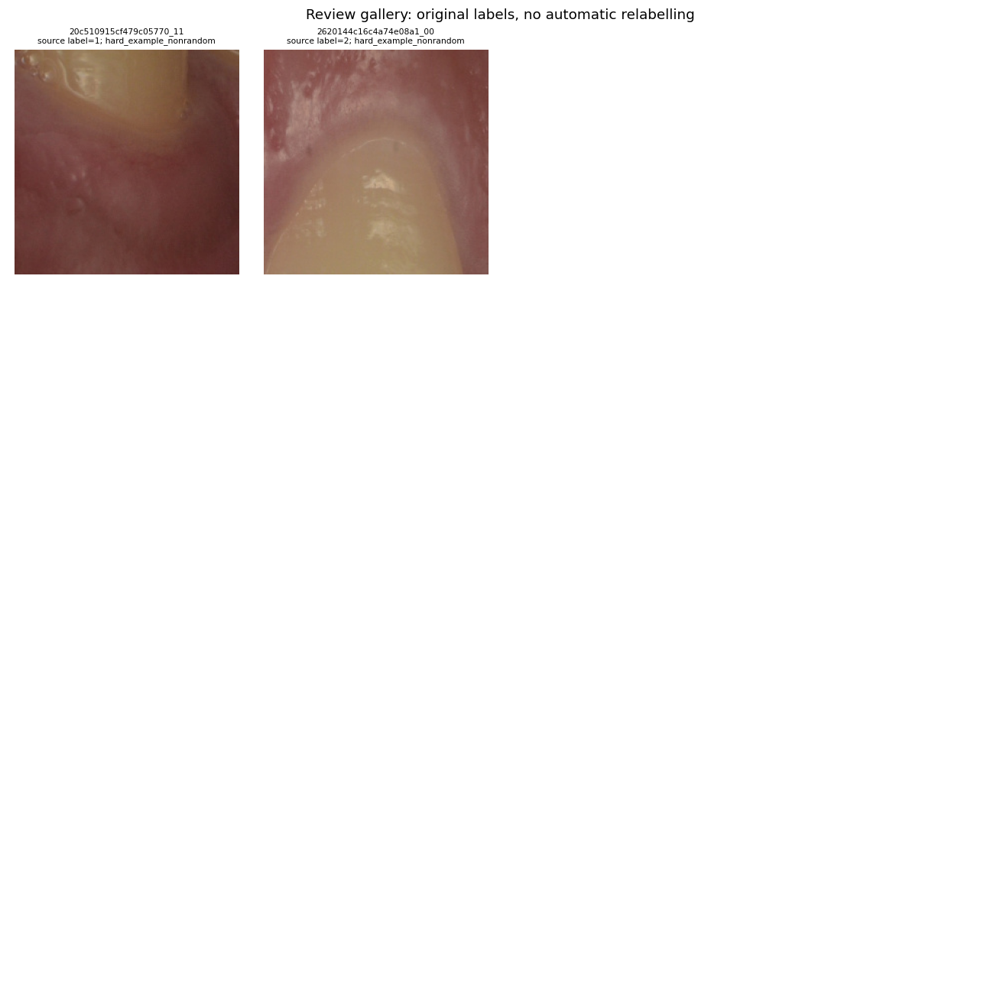

Review sheet rows: 114 | All no-visible included: 49


In [6]:
selected = joined[joined.class_id.eq(0)].copy()
selected['selection_reason']='all_no_visible'
for cls in [1,2]:
    sample=joined[joined.class_id.eq(cls)].sample(n=24,random_state=42).copy()
    sample['selection_reason']='seeded_random_class_'+str(cls)
    selected=pd.concat([selected,sample])
hard=joined.sort_values(['wrong_count'],ascending=False,kind='stable').head(24).copy()
hard['selection_reason']='hard_example_nonrandom'
selected=pd.concat([selected,hard]).reset_index().drop_duplicates('crop_id').set_index('crop_id')
review=selected[['parent_id','class_id','class_name','source_image','local_path','selection_reason']].copy()
for field in ['reviewer_id','reviewed_appearance','confidence','visibility_issue','comment']:
    review[field]=''
review.to_csv(OUT/'reviewer_sheet.csv')
joined.to_csv(OUT/'all_validation_diagnostics.csv')
for page, start in enumerate(range(0,len(selected),16),1):
    subset=selected.iloc[start:start+16]
    fig,axes=plt.subplots(4,4,figsize=(12,12))
    for ax in axes.flat: ax.axis('off')
    for ax,(crop_id,row) in zip(axes.flat,subset.iterrows()):
        with Image.open(RAW/row.local_path) as image: ax.imshow(image)
        ax.set_title(f'{crop_id}\nsource label={row.class_id}; {row.selection_reason}',fontsize=7)
    fig.suptitle('Review gallery: original labels, no automatic relabelling');fig.tight_layout()
    fig.savefig(OUT/f'review_page_{page:02d}.png');plt.show()
print('Review sheet rows:',len(review),'| All no-visible included:',int((review.class_id==0).sum()))

## 7. Source-parent and crop geometry panels
Show the full source photograph with the selected ROI rectangle, followed by its raw-source crop. These panels support technical inspection; box coverage is not a tissue segmentation mask.

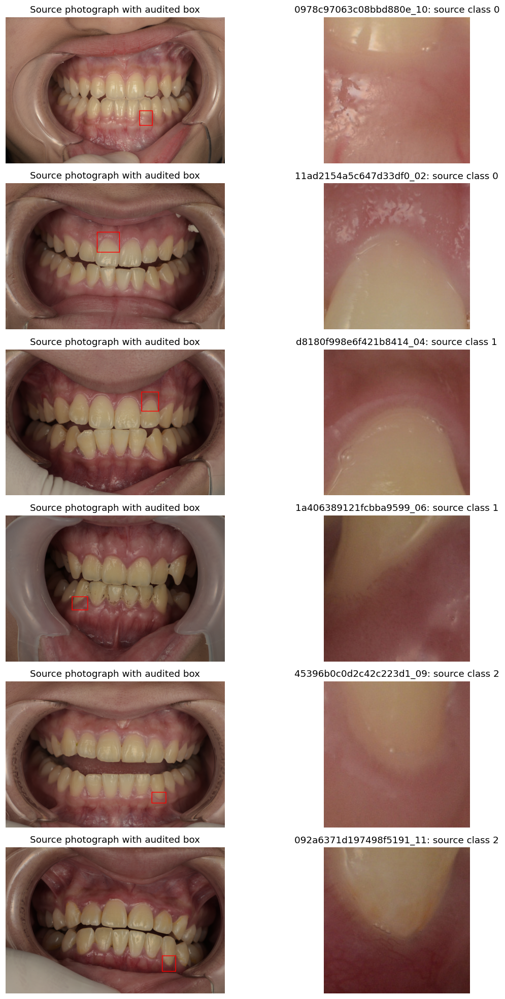

In [7]:
representatives=selected.reset_index().groupby('class_id',group_keys=False).head(2)
fig,axes=plt.subplots(len(representatives),2,figsize=(12,3*len(representatives)))
for index,row in enumerate(representatives.itertuples()):
    path=ROOT/row.source_image
    assert sha(path)==row.source_sha256
    with Image.open(path) as image:
        original_size=image.size
        preview=image.convert('RGB');preview.thumbnail((1200,800))
        bounds=json.loads(row.raw_bounds)
        scale=np.array([preview.width/original_size[0],preview.height/original_size[1]]*2)
        ImageDraw.Draw(preview).rectangle(tuple(np.array(bounds)*scale),outline='red',width=4)
        axes[index,0].imshow(preview)
    with Image.open(RAW/row.local_path) as image: axes[index,1].imshow(image)
    axes[index,0].set_title('Source photograph with audited box')
    axes[index,1].set_title(f'{row.crop_id}: source class {row.class_id}')
    for ax in axes[index]:ax.axis('off')
fig.tight_layout();fig.savefig(OUT/'parent_crop_geometry.png');plt.show()

## 8. Technical verdict and next experiment gate
Prediction joins, probabilities, checkpoint selection, source-label mapping, crop bytes and split locks are checked above. This does not certify clinical label validity, patient independence, or that every original-source crop contains sufficient gingival tissue.

In [8]:
summary={'validation_crops':len(joined),'validation_groups':joined.group_id.nunique(),
         'verified_prediction_runs':len(results),'all_models_wrong':int(joined.all_wrong.sum()),
         'unanimous_wrong':int(joined.unanimous_wrong.sum()),
         'no_visible_validation_groups':joined[joined.class_id.eq(0)].group_id.nunique(),
         'technical_checks':'passed for the explicitly executed assertions',
         'clinical_review':'pending; no labels changed','test_images_opened':0,
         'raw_manifest_sha256':sha(RAW/'manifest.csv'),'prediction_evidence':evidence}
save_json(OUT/'summary.json',summary)
display(pd.Series({k:v for k,v in summary.items() if k!='prediction_evidence'}).to_frame('value'))
display(Markdown('**Decision:** no failed technical assertion in this audit. Clinical ambiguity remains unverified. '
                 'A bounded patch-readout/adaptation study is eligible for later implementation; '
                 'do not claim a data-label ceiling or a solved clinical task from model disagreement.'))

,value
validation_crops,1920
validation_groups,160
verified_prediction_runs,10
all_models_wrong,99
unanimous_wrong,79
no_visible_validation_groups,23
technical_checks,passed for the explicitly executed assertions
clinical_review,pending; no labels changed
test_images_opened,0
raw_manifest_sha256,b9feaaceb4b9ea94ad540b553927ffb7f67e731098f7a7...


**Decision:** no failed technical assertion in this audit. Clinical ambiguity remains unverified. A bounded patch-readout/adaptation study is eligible for later implementation; do not claim a data-label ceiling or a solved clinical task from model disagreement.

## 9. Collected evidence and presentation summary

The common-error population is a review priority, not proof that labels are wrong. Report the small minority support and preserve the full validation population.

In [1]:

from pathlib import Path
import json, pandas as pd
from IPython.display import display, Markdown
root = Path.cwd()
out = root / 'docs/reports/post09/gingival'
summary = json.loads((out / 'summary.json').read_text())
data = pd.read_csv(out / 'all_validation_diagnostics.csv')
display(data.groupby('class_name').agg(crops=('crop_id','size'), all_wrong=('all_wrong','sum'),
                                      unanimous_wrong=('unanimous_wrong','sum'), all_correct=('all_correct','sum')))
worker = (root / 'src/dentalselfie/recovery_worker.py').read_text()
assert 'transforms.Resize((224, 224)' in worker
assert '(0.485,0.456,0.406), (0.229,0.224,0.225)' in worker
print('Recovery worker contract inspected: 224 RGB crops, ImageNet normalization.')
display(Markdown(f"**Observed:** {summary['all_models_wrong']} crops were wrong for every verified model; "
                 f"{summary['unanimous_wrong']} had unanimous wrong predictions. "
                 "Technical checks passed within their stated scope. Qualified clinical review remains pending. "
                 "Patch-readout and partial-adaptation experiments remain exploratory next stages."))


,crops,all_wrong,unanimous_wrong,all_correct
class_name,,,,
marked_inflammation,939,23,13,408
mild_inflammation,932,62,61,111
no_visible_inflammation,49,14,5,0


Recovery worker contract inspected: 224 RGB crops, ImageNet normalization.


**Observed:** 99 crops were wrong for every verified model; 79 had unanimous wrong predictions. Technical checks passed within their stated scope. Qualified clinical review remains pending. Patch-readout and partial-adaptation experiments remain exploratory next stages.